# Decision Tree (classification)

A tree of yes/no questions about the features. At each node it asks `feature ≤ threshold?`, sends the point left or right, and at a leaf predicts the majority class. The whole algorithm is how to choose the questions: **greedy search for the split that makes the two sides as pure as possible**.

Purity is measured with **Gini impurity**

$$G(S) = 1 - \sum_c p_c^2$$

(0 = all one class, 0.5 = a 50/50 mix of two classes). A split is scored by the size-weighted Gini of its two children; the best split is the one with the lowest score, i.e. the biggest drop from the parent.

Growth stops at `max_depth`, at a pure node, or when a node has fewer than `min_samples_split` points.

This notebook is self-contained: implementation, visuals, scikit-learn check and tests.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

`_best_split` is the heart: for every feature and every candidate threshold, compute the weighted Gini of the two sides and keep the best. It is the simple brute-force version, `O(n²·d)` per node. Folders `07`, `21`, `22` use the faster sort-and-cumulative-sum trick.

In [2]:
from collections import Counter

import numpy as np


class _Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, value=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value  # set only on leaf nodes

    def is_leaf(self):
        return self.value is not None


def _gini(y):
    counts = np.bincount(y)
    probs = counts / len(y)
    return 1.0 - np.sum(probs**2)


class DecisionTreeClassifier:
    """CART decision tree for classification, splitting on Gini impurity."""

    def __init__(self, max_depth=5, min_samples_split=2):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.root = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)
        self.root = self._grow(X, y, depth=0)
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return np.array([self._traverse(x, self.root) for x in X])

    def _grow(self, X, y, depth):
        n_samples, n_features = X.shape
        n_labels = len(set(y))

        if depth >= self.max_depth or n_labels == 1 or n_samples < self.min_samples_split:
            return _Node(value=Counter(y).most_common(1)[0][0])

        best_feature, best_threshold = self._best_split(X, y, n_features)
        if best_feature is None:
            return _Node(value=Counter(y).most_common(1)[0][0])

        left_mask = X[:, best_feature] <= best_threshold
        left = self._grow(X[left_mask], y[left_mask], depth + 1)
        right = self._grow(X[~left_mask], y[~left_mask], depth + 1)
        return _Node(feature=best_feature, threshold=best_threshold, left=left, right=right)

    def _best_split(self, X, y, n_features):
        best_gain = 0.0
        best_feature, best_threshold = None, None
        parent_gini = _gini(y)

        for feature in range(n_features):
            thresholds = np.unique(X[:, feature])
            for threshold in thresholds:
                left_mask = X[:, feature] <= threshold
                if left_mask.sum() == 0 or (~left_mask).sum() == 0:
                    continue
                n = len(y)
                gini_left = _gini(y[left_mask])
                gini_right = _gini(y[~left_mask])
                weighted = (left_mask.sum() / n) * gini_left + ((~left_mask).sum() / n) * gini_right
                gain = parent_gini - weighted
                if gain > best_gain:
                    best_gain = gain
                    best_feature, best_threshold = feature, threshold

        return best_feature, best_threshold

    def _traverse(self, x, node):
        if node.is_leaf():
            return node.value
        if x[node.feature] <= node.threshold:
            return self._traverse(x, node.left)
        return self._traverse(x, node.right)

## See it work

### 1. What Gini impurity measures

For two classes, Gini is `2p(1−p)`: zero when the node is pure, largest at 50/50. A good split moves points so each child is closer to one of the extremes.

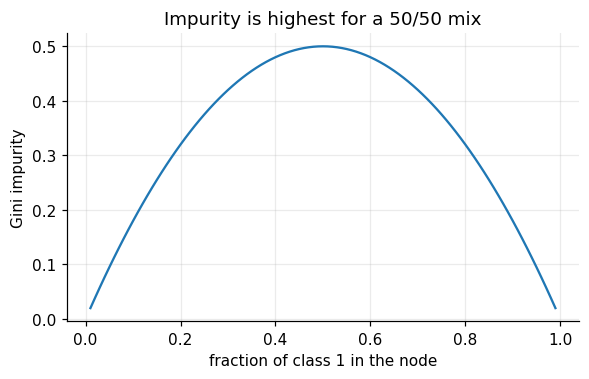

In [3]:
p = np.linspace(0.01, 0.99, 99)
gini_curve = [_gini(np.array([0] * int(round(100 * (1 - q))) + [1] * int(round(100 * q)))) for q in p]
plt.figure(figsize=(6, 3.4))
plt.plot(p, gini_curve); plt.xlabel("fraction of class 1 in the node"); plt.ylabel("Gini impurity")
plt.title("Impurity is highest for a 50/50 mix"); plt.show()

### 2. Finding the best split for one feature

Iris, petal length. For every possible threshold we compute the weighted Gini of the left and right groups. The tree picks the lowest point of the bottom curve. That cut (around 2.5 cm) isolates one species perfectly.

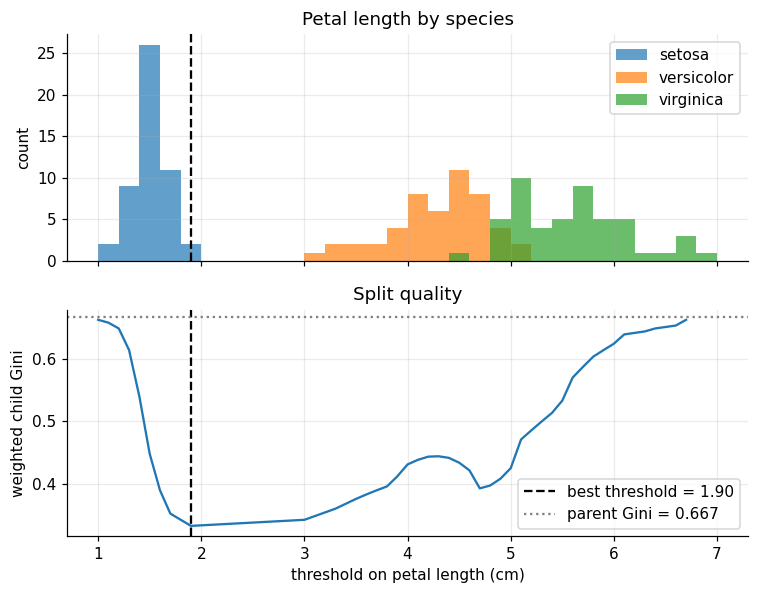

In [4]:
from sklearn.datasets import load_iris

iris = load_iris()
x, y = iris.data[:, 2], iris.target
thr = np.unique(x)[:-1]
score = [(((x <= t).mean()) * _gini(y[x <= t]) + ((x > t).mean()) * _gini(y[x > t])) for t in thr]
best = thr[int(np.argmin(score))]

fig, (a, b) = plt.subplots(2, 1, figsize=(7, 5.5), sharex=True)
for c, name in enumerate(iris.target_names):
    a.hist(x[y == c], bins=np.arange(1, 7.1, 0.2), alpha=0.7, label=name)
a.axvline(best, color="k", ls="--"); a.legend(); a.set_ylabel("count"); a.set_title("Petal length by species")
b.plot(thr, score); b.axvline(best, color="k", ls="--", label=f"best threshold = {best:.2f}")
b.axhline(_gini(y), color="gray", ls=":", label=f"parent Gini = {_gini(y):.3f}")
b.set(xlabel="threshold on petal length (cm)", ylabel="weighted child Gini", title="Split quality"); b.legend()
plt.tight_layout(); plt.show()

### 3. The tree as readable rules

A fitted tree is just nested `if`s. This helper prints one (it only uses the `_Node` objects the model stores). Note the last split predicts virginica on both sides: the greedy search still found it lowers impurity, even though it does not change the prediction.

In [5]:
def show_tree(node, names, indent=""):
    if node.is_leaf():
        print(f"{indent}-> {iris.target_names[node.value]}")
        return
    print(f"{indent}if {names[node.feature]} <= {node.threshold:.2f}:")
    show_tree(node.left, names, indent + "    ")
    print(f"{indent}else:")
    show_tree(node.right, names, indent + "    ")

tree = DecisionTreeClassifier(max_depth=3).fit(iris.data, iris.target)
show_tree(tree.root, iris.feature_names)

if petal length (cm) <= 1.90:
    -> setosa
else:
    if petal width (cm) <= 1.70:
        if petal length (cm) <= 4.90:
            -> versicolor
        else:
            -> virginica
    else:
        if petal length (cm) <= 4.80:
            -> virginica
        else:
            -> virginica


### 4. Decision boundaries get more complicated with depth

Using two features (petal length and width) so we can draw the plane. A depth-1 tree makes one straight cut; deeper trees add more axis-aligned cuts, always **rectangles**, because every split looks at a single feature.

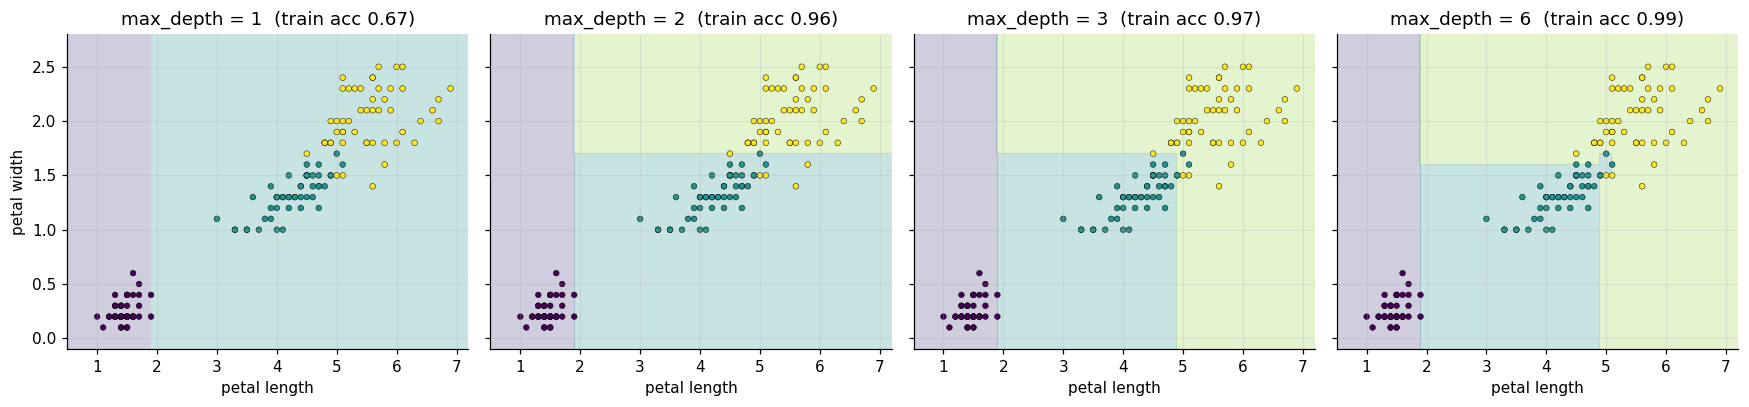

In [6]:
X2 = iris.data[:, 2:4]
gx, gy = np.meshgrid(np.linspace(0.5, 7.2, 200), np.linspace(-0.1, 2.8, 200))
grid = np.c_[gx.ravel(), gy.ravel()]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=True)
for ax, d in zip(axes, [1, 2, 3, 6]):
    t = DecisionTreeClassifier(max_depth=d).fit(X2, y)
    ax.contourf(gx, gy, t.predict(grid).reshape(gx.shape), alpha=0.25, cmap="viridis", levels=[-0.5, 0.5, 1.5, 2.5])
    ax.scatter(*X2.T, c=y, cmap="viridis", s=14, edgecolor="k", linewidth=0.3)
    ax.set_title(f"max_depth = {d}  (train acc {(t.predict(X2) == y).mean():.2f})"); ax.set_xlabel("petal length")
axes[0].set_ylabel("petal width")
plt.tight_layout(); plt.show()

### 5. Overfitting: the depth knob

On noisy data (two interleaved moons), training accuracy keeps climbing with depth, because a deep tree can carve out every training point. Test accuracy peaks early and then **falls**: the tree has memorised noise. Pick the depth where test accuracy is best, or prune.

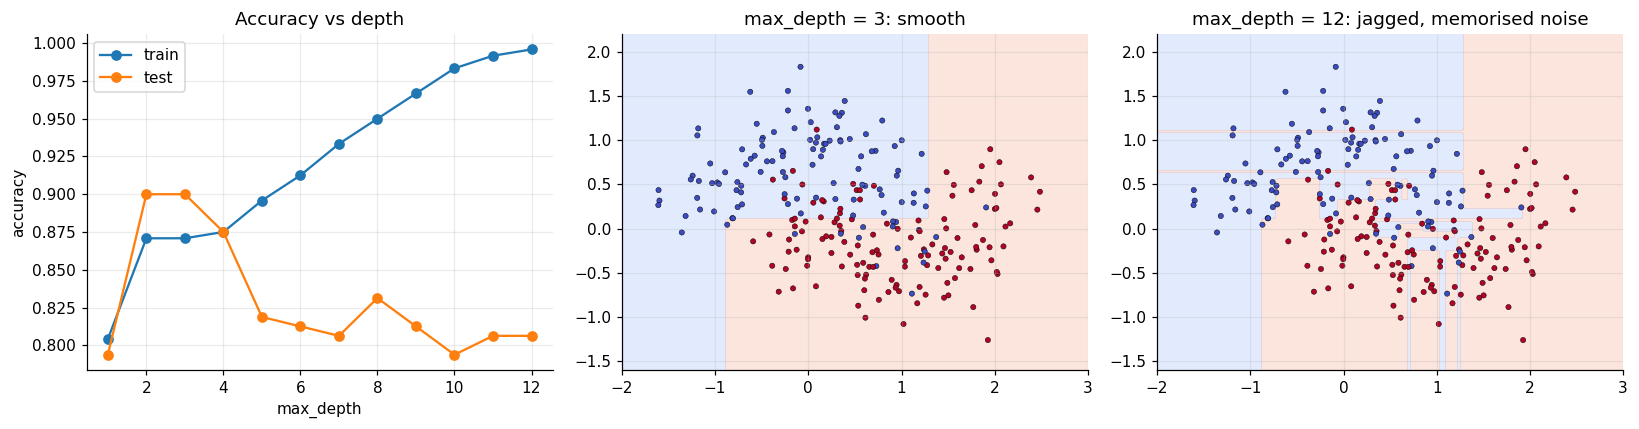

In [7]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

Xm, ym = make_moons(n_samples=400, noise=0.35, random_state=0)
Xtr, Xte, ytr, yte = train_test_split(Xm, ym, test_size=0.4, random_state=0)
depths = range(1, 13)
train_acc, test_acc = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d).fit(Xtr, ytr)
    train_acc.append((t.predict(Xtr) == ytr).mean()); test_acc.append((t.predict(Xte) == yte).mean())

gx, gy = np.meshgrid(np.linspace(-2, 3, 160), np.linspace(-1.6, 2.2, 160))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(list(depths), train_acc, "o-", label="train"); axes[0].plot(list(depths), test_acc, "o-", label="test")
axes[0].set(xlabel="max_depth", ylabel="accuracy", title="Accuracy vs depth"); axes[0].legend()
for ax, d in zip(axes[1:], [3, 12]):
    t = DecisionTreeClassifier(max_depth=d).fit(Xtr, ytr)
    ax.contourf(gx, gy, t.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape), alpha=0.25, cmap="coolwarm", levels=[-0.5, 0.5, 1.5])
    ax.scatter(*Xtr.T, c=ytr, cmap="coolwarm", s=12, edgecolor="k", linewidth=0.3)
    ax.set_title(f"max_depth = {d}: " + ("smooth" if d == 3 else "jagged, memorised noise"))
plt.tight_layout(); plt.show()

## Check against scikit-learn

Same data, same depth, same Gini criterion. Ties between equally good splits can be broken differently, so accuracy should be close, not necessarily identical.

In [8]:
from sklearn.tree import DecisionTreeClassifier as SklearnTree

X_train, X_test, y_train, y_test = train_test_split(iris.data, iris.target, test_size=0.3, random_state=42)
ours = DecisionTreeClassifier(max_depth=4).fit(X_train, y_train)
theirs = SklearnTree(max_depth=4, criterion="gini", random_state=0).fit(X_train, y_train)
acc_ours, acc_theirs = (ours.predict(X_test) == y_test).mean(), (theirs.predict(X_test) == y_test).mean()
print("iris test accuracy: ours=%.4f sklearn=%.4f" % (acc_ours, acc_theirs))
assert abs(acc_ours - acc_theirs) < 0.1
print("match")

iris test accuracy: ours=0.9556 sklearn=1.0000
match


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [9]:
import numpy as np


def test_gini_pure_and_mixed():
    assert _gini(np.array([0, 0, 0])) == 0.0
    assert _gini(np.array([0, 1])) == 0.5


def test_simple_threshold_split():
    X = np.array([[1], [2], [3], [8], [9], [10]], dtype=float)
    y = np.array([0, 0, 0, 1, 1, 1])
    model = DecisionTreeClassifier(max_depth=3).fit(X, y)
    preds = model.predict(X)
    assert (preds == y).all()


def test_iris_like_accuracy():
    from sklearn.datasets import load_iris
    from sklearn.model_selection import train_test_split

    data = load_iris()
    X_train, X_test, y_train, y_test = train_test_split(
        data.data, data.target, test_size=0.3, random_state=0
    )
    model = DecisionTreeClassifier(max_depth=4).fit(X_train, y_train)
    preds = model.predict(X_test)
    accuracy = (preds == y_test).mean()
    assert accuracy > 0.9, accuracy

In [10]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_gini_pure_and_mixed
PASS test_simple_threshold_split
PASS test_iris_like_accuracy

all 3 tests passed


## Takeaways

- **Use it when** you want an interpretable model, have mixed feature types, or want no feature scaling (splits only compare a feature to a threshold, so scaling is irrelevant).
- **Weakness:** a single tree is **high variance**: change a few training points and the tree can change completely, and it overfits easily (section 5). That is exactly what `18_bagging`, `19_random_forest` and the boosting folders fix by combining many trees.
- **Limits:** only axis-aligned cuts, so a diagonal boundary needs many steps; cannot extrapolate beyond the training range.
- **Interview line:** *"Greedy recursive partitioning: at each node pick the (feature, threshold) with the largest impurity decrease, Gini `1 − Σp²`; stop on depth or purity. Controls: `max_depth`, `min_samples_split`."*